# Modèle de Cramér-Lundberg avec un processus de comptage « à impact »

**Note d'analyse pour le N+1**

On nous demande d'étudier ce que deviennent les propriétés du modèle de Cramér-Lundberg

$$R_t = u + ct - \sum_{i=1}^{N_t} Y_i$$

lorsque le processus de Poisson $N$ est remplacé par un modèle à impact, où chaque sinistre « spontané » peut déclencher d'autres sinistres peu de temps après (contrats où un sinistre en entraîne d'autres : catastrophes naturelles, cyber, soins dentaires en série...).

Plan :
1. Rappels sur le modèle de Poisson (référence)
2. Le modèle à impact : construction et simulation
3. Espérance du nombre de sinistres à toute date
4. Rôle et impact des paramètres
5. Montants des sinistres : lois discrètes et continues
6. Probabilité de ruine
7. Propriétés du cours : ce qui reste vrai, ce qui ne l'est plus
8. Synthèse

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2024)

T = 10.0
mu = 1.0
alpha = 0.8
beta = 1.2
facteur = 2

## 1. Rappels : le modèle de Poisson

Avec $N$ Poisson d'intensité $\mu$ et des $Y_i$ i.i.d. indépendants de $N$, de moyenne $m$ :

- $\mathbb E[N_t]=\operatorname{Var}(N_t)=\mu t$, accroissements indépendants et stationnaires, sauts de taille 1 ;
- Wald : $\mathbb E[S_t]=\mu t\, m$ et $\operatorname{Var}(S_t)=\mu t\,\mathbb E[Y^2]$ ;
- condition de profit net : $c>\mu m$, on écrit $c=(1+\eta)\mu m$ ;
- Lundberg : $\psi(u)\le e^{-Ru}$ avec $\mu(M_Y(R)-1)=cR$ ;
- sinistres exponentiels : $\psi(u)=\frac{1}{1+\eta}\exp\!\big(-\frac{\eta u}{(1+\eta)m}\big)$.

## 2. Le modèle à impact

On tire une mesure de Poisson d'intensité 1 sur $[0,T]\times[0,M]$ (algorithme 1 du sujet), puis :

- **sinistres spontanés** : les points sous la hauteur $\mu$, $N^{(1)}_t=\sum_i \mathbf 1_{\theta_i\le\mu}\mathbf 1_{t_i\le t}$, c'est un Poisson($\mu$) ;
- **sinistres induits** : chaque sinistre spontané en $t_{i_1}$ crée une zone d'impact $\{\mu<\theta\le\mu+\Phi(t-t_{i_1})\}$ avec le noyau exponentiel $\Phi(u)=\alpha e^{-\beta u}$ ; un point qui tombe dedans est un sinistre induit :

$$N^{(2)}_t = 2\sum_{i_1}\sum_{i_2:\,t_{i_2}>t_{i_1}}\mathbf 1_{\theta_{i_1}\le\mu}\,\mathbf 1_{\mu<\theta_{i_2}\le\mu+\Phi(t_{i_2}-t_{i_1})}\,\mathbf 1_{t_{i_2}\le t}.$$

Contraintes : $0<\mu$, $0<\alpha<\beta$ et $M\ge\mu+\alpha$ (la zone d'impact doit tenir dans le rectangle, on prend $M=\mu+\alpha$).
C'est la construction par thinning (Chen) : on garde un point si sa hauteur est sous l'intensité.

Le facteur 2 du sujet est gardé dans la variable `facteur` ; dans Hillairet & Réveillac (2024, Prop. 5.2) la 2e génération est pondérée par $\frac1{2!}$, ce qui correspond à `facteur = 1`.

In [2]:
def Phi(u, alpha, beta):
    return alpha * np.exp(-beta * np.clip(u, 0, None)) * (u > 0)

def simule_P(T, M, rng):
    n = rng.poisson(M * T)
    t = np.sort(rng.uniform(0, T, n))
    theta = rng.uniform(0, M, n)
    return t, theta

def sauts_N(t, theta, mu, alpha, beta, facteur=facteur):
    parent = theta <= mu
    dt = t[None, :] - t[:, None]
    dans_bosse = (dt > 0) & (theta[None, :] > mu) & (theta[None, :] - mu <= Phi(dt, alpha, beta))
    nb_parents = (dans_bosse & parent[:, None]).sum(axis=0)
    return parent.astype(int), facteur * nb_parents

def simule_impact(T, mu, alpha, beta, rng, facteur=facteur):
    t, theta = simule_P(T, mu + alpha, rng)
    s1, s2 = sauts_N(t, theta, mu, alpha, beta, facteur)
    s = s1 + s2
    return t[s > 0], s[s > 0]

def simule_poisson(T, mu, rng):
    n = rng.poisson(mu * T)
    return np.sort(rng.uniform(0, T, n)), np.ones(n, dtype=int)

def comptage(temps, sauts, grille):
    return np.r_[0, np.cumsum(sauts)][np.searchsorted(temps, grille, side="right")]

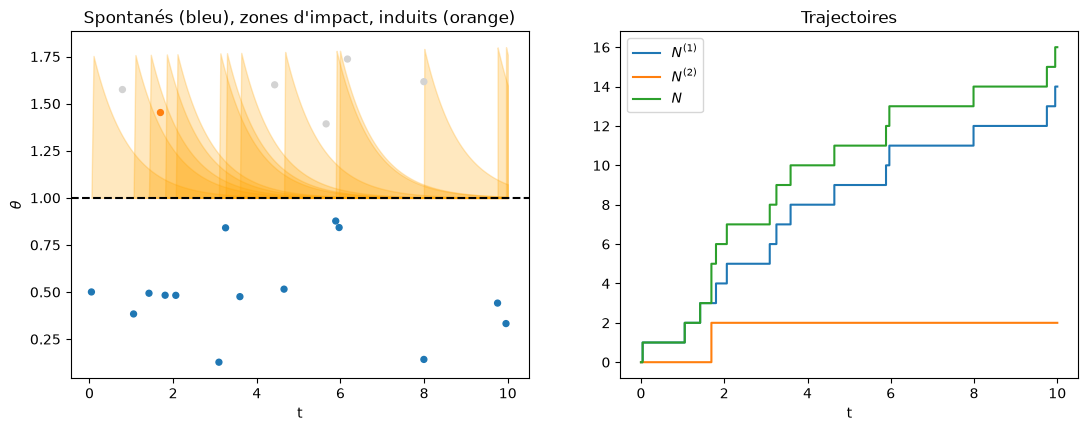

plus grand saut : 2


In [3]:
t, theta = simule_P(T, mu + alpha, rng)
s1, s2 = sauts_N(t, theta, mu, alpha, beta)
grille = np.linspace(0, T, 1000)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for i in np.where(theta <= mu)[0]:
    x = np.linspace(t[i], T, 200)
    ax[0].fill_between(x, mu, mu + Phi(x - t[i], alpha, beta), color="orange", alpha=0.25)
couleur = np.where(theta <= mu, "tab:blue", np.where(s2 > 0, "tab:orange", "lightgrey"))
ax[0].scatter(t, theta, c=couleur, s=18)
ax[0].axhline(mu, ls="--", c="k")
ax[0].set(xlabel="t", ylabel=r"$\theta$", title="Spontanés (bleu), zones d'impact, induits (orange)")
ax[1].step(grille, comptage(t, s1, grille), label=r"$N^{(1)}$")
ax[1].step(grille, comptage(t, s2, grille), label=r"$N^{(2)}$")
ax[1].step(grille, comptage(t, s1 + s2, grille), label=r"$N$")
ax[1].legend(); ax[1].set(xlabel="t", title="Trajectoires")
plt.show()
print("plus grand saut :", (s1 + s2).max())

Un point peut tomber dans les zones d'impact de plusieurs sinistres spontanés : il est alors compté plusieurs fois et $N$ fait un saut de taille $>1$. Ce n'est donc pas un processus de comptage au sens strict (cf. Remarque 5.4 de Hillairet & Réveillac). Dans la suite, un saut de taille $k$ correspond à $k$ sinistres survenus au même instant. Avec `facteur = 2`, chaque sinistre induit compte déjà pour 2 ; la colonne `P(multi)` de la partie 4 mesure la probabilité qu'au moins un sinistre soit induit par plusieurs sinistres spontanés à la fois.

## 3. Espérance du nombre de sinistres à toute date

$\mathbb E[N^{(1)}_t]=\mu t$ (aire de $[0,t]\times[0,\mu]$). Pour $N^{(2)}$, la formule de Mecke donne

$$\mathbb E[N^{(2)}_t]=2\int_0^t\!\!\int_0^{t_2}\!\!\int_0^M\!\!\int_0^M \mathbf 1_{\theta_1\le\mu}\mathbf 1_{\mu<\theta_2\le\mu+\Phi(t_2-t_1)}\,d\theta_2\,d\theta_1\,dt_1\,dt_2
=2\mu\int_0^t\!\!\int_0^{t_2}\alpha e^{-\beta(t_2-t_1)}dt_1\,dt_2$$

$$=2\mu\frac{\alpha}{\beta}\int_0^t\big(1-e^{-\beta t_2}\big)dt_2=2\,\frac{\mu\alpha}{\beta}\Big(t-\frac{1-e^{-\beta t}}{\beta}\Big).$$

Donc
$$\boxed{\mathbb E[N_t]=\mu t+2\,\frac{\mu\alpha}{\beta}\Big(t-\frac{1-e^{-\beta t}}{\beta}\Big)}\qquad\text{et}\qquad \frac{\mathbb E[N_t]}{t}\xrightarrow[t\to\infty]{}\mu\Big(1+\frac{2\alpha}{\beta}\Big).$$

Pour comparaison, le processus de Hawkes à noyau exponentiel ($\lambda_t=\mu+\sum_{t_i<t}\alpha e^{-\beta(t-t_i)}$, condition de stabilité $\alpha<\beta$) vérifie $m'=-(\beta-\alpha)m+\beta\mu$ pour $m(t)=\mathbb E[\lambda_t]$, d'où
$$\mathbb E[H_t]=\frac{\mu\beta}{\beta-\alpha}t-\frac{\mu\alpha}{(\beta-\alpha)^2}\big(1-e^{-(\beta-\alpha)t}\big).$$
Au premier ordre en $\alpha$, $\mathbb E[H_t]\approx\mu t+\frac{\mu\alpha}{\beta}(t-\frac{1-e^{-\beta t}}{\beta})$ : le modèle à impact correspond aux deux premières générations d'un Hawkes (sans les sinistres induits par des sinistres induits).

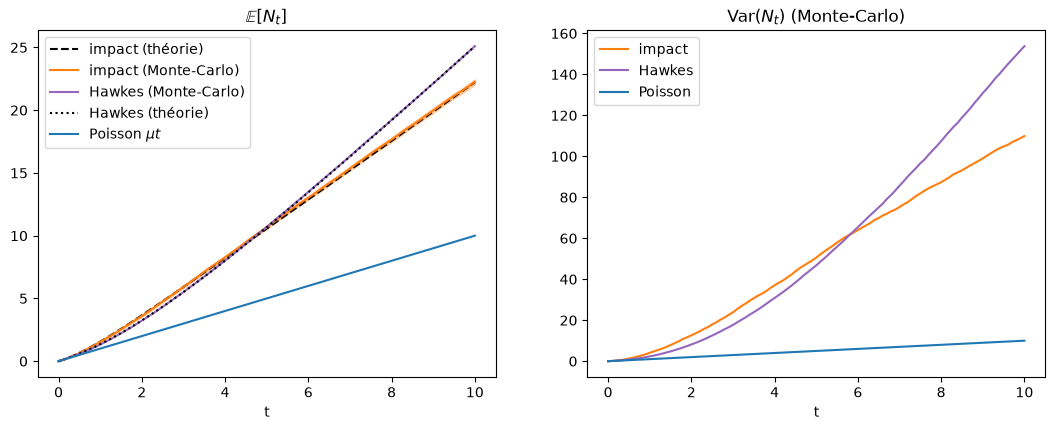

E[N_T] MC = 22.25 ± 0.21   théorie = 22.22
E[H_T] MC = 25.10   théorie = 25.09
Var(N_T) = 109.9   Var(H_T) = 153.8   Poisson : 10.0


In [4]:
def esperance_impact(t, mu, alpha, beta, facteur=facteur):
    return mu * t + facteur * mu * alpha / beta * (t - (1 - np.exp(-beta * t)) / beta)

def esperance_hawkes(t, mu, alpha, beta):
    return mu * beta / (beta - alpha) * t - mu * alpha / (beta - alpha) ** 2 * (1 - np.exp(-(beta - alpha) * t))

def hawkes_ogata(T, mu, alpha, beta, rng):
    s, sauts, exc = 0.0, [], 0.0
    while True:
        borne = mu + exc
        w = rng.exponential(1 / borne)
        s += w
        if s > T:
            return np.array(sauts), np.ones(len(sauts), dtype=int)
        exc *= np.exp(-beta * w)
        if rng.uniform() * borne <= mu + exc:
            sauts.append(s)
            exc += alpha

K = 10000
grille = np.linspace(0, T, 101)
Ni = np.array([comptage(*simule_impact(T, mu, alpha, beta, rng), grille) for _ in range(K)])
Nh = np.array([comptage(*hawkes_ogata(T, mu, alpha, beta, rng), grille) for _ in range(K)])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ic = 1.96 * Ni.std(axis=0) / np.sqrt(K)
ax[0].fill_between(grille, Ni.mean(axis=0) - ic, Ni.mean(axis=0) + ic, alpha=0.3, color="tab:orange")
ax[0].plot(grille, esperance_impact(grille, mu, alpha, beta), "k--", label="impact (théorie)")
ax[0].plot(grille, Ni.mean(axis=0), c="tab:orange", label="impact (Monte-Carlo)")
ax[0].plot(grille, Nh.mean(axis=0), c="tab:purple", label="Hawkes (Monte-Carlo)")
ax[0].plot(grille, esperance_hawkes(grille, mu, alpha, beta), "k:", label="Hawkes (théorie)")
ax[0].plot(grille, mu * grille, c="tab:blue", label=r"Poisson $\mu t$")
ax[0].set(xlabel="t", title=r"$\mathbb{E}[N_t]$"); ax[0].legend()
ax[1].plot(grille, Ni.var(axis=0), c="tab:orange", label="impact")
ax[1].plot(grille, Nh.var(axis=0), c="tab:purple", label="Hawkes")
ax[1].plot(grille, mu * grille, c="tab:blue", label="Poisson")
ax[1].set(xlabel="t", title=r"$\mathrm{Var}(N_t)$ (Monte-Carlo)"); ax[1].legend()
plt.show()

print(f"E[N_T] MC = {Ni[:, -1].mean():.2f} ± {1.96 * Ni[:, -1].std() / np.sqrt(K):.2f}   théorie = {esperance_impact(T, mu, alpha, beta):.2f}")
print(f"E[H_T] MC = {Nh[:, -1].mean():.2f}   théorie = {esperance_hawkes(T, mu, alpha, beta):.2f}")
print(f"Var(N_T) = {Ni[:, -1].var():.1f}   Var(H_T) = {Nh[:, -1].var():.1f}   Poisson : {mu * T:.1f}")

La formule théorique est dans l'intervalle de confiance Monte-Carlo sur toute la grille. Au début $\mathbb E[N_t]\approx\mu t$ (pas encore d'impact), puis la pente augmente jusqu'à $\mu(1+2\alpha/\beta)$. La variance est très supérieure à l'espérance (surdispersion) alors qu'elles sont égales pour Poisson.

## 4. Rôle et impact des paramètres

- $\mu$ : fréquence des sinistres spontanés (comme l'intensité du modèle de Poisson) ;
- $\alpha$ : force de l'impact juste après un sinistre (hauteur de la zone d'impact) ;
- $\beta$ : vitesse à laquelle l'impact s'éteint, $1/\beta$ est la durée typique de l'effet ;
- $\alpha/\beta=\int_0^\infty\Phi$ : nombre moyen de sinistres induits par un sinistre spontané (pondéré par `facteur`).

Dans le modèle à impact les sinistres induits n'induisent rien, donc $\mathbb E[N_t]$ reste fini même si $\alpha\ge\beta$ ; la condition $\alpha<\beta$ est celle de stabilité du Hawkes et on la garde pour comparer les deux modèles.

   mu  alpha  beta |  E[N_T]  théorie     Var  Var/E  P(multi)
  0.5    0.8   1.2 |   11.01    11.11    45.1   4.09      0.40


  1.0    0.8   1.2 |   22.29    22.22   116.2   5.21      0.73
  2.0    0.8   1.2 |   44.62    44.44   304.2   6.82      0.94


  1.0    0.2   1.2 |   12.94    13.06    29.9   2.31      0.30
  1.0    0.6   1.2 |   18.98    19.17    79.5   4.19      0.64


  1.0    1.0   1.2 |   25.32    25.28   142.9   5.64      0.80
  1.0    0.8   0.9 |   25.80    25.80   164.6   6.38      0.82


  1.0    0.8   1.2 |   22.19    22.22   107.9   4.86      0.73
  1.0    0.8   3.0 |   15.01    15.16    38.8   2.58      0.35


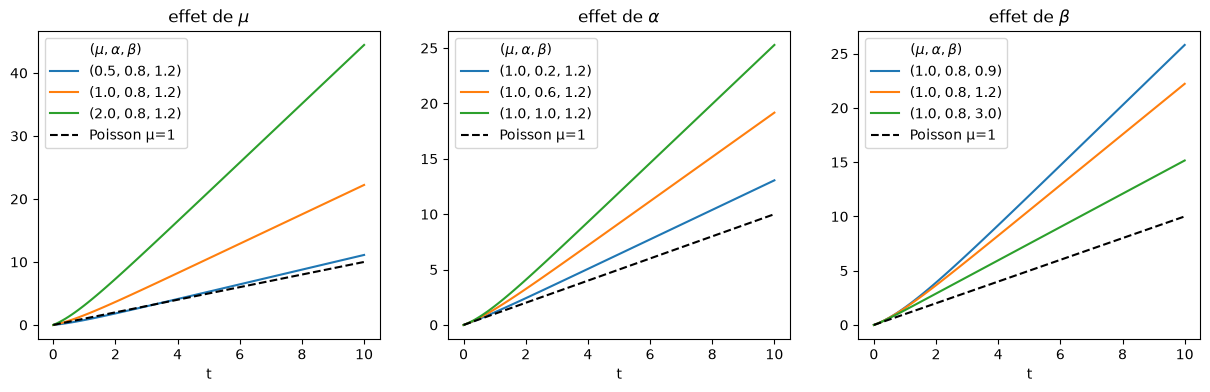

In [5]:
def resume(mu, alpha, beta, K=4000):
    NT, gros = np.empty(K), np.empty(K)
    for k in range(K):
        tk, sk = simule_impact(T, mu, alpha, beta, rng)
        NT[k] = sk.sum()
        gros[k] = np.any(sk > facteur)
    return NT.mean(), NT.var(), gros.mean()

configs = {
    r"$\mu$": [(m, alpha, beta) for m in [0.5, 1.0, 2.0]],
    r"$\alpha$": [(mu, a, beta) for a in [0.2, 0.6, 1.0]],
    r"$\beta$": [(mu, alpha, b) for b in [0.9, 1.2, 3.0]],
}

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
print(f"{'mu':>5} {'alpha':>6} {'beta':>5} | {'E[N_T]':>7} {'théorie':>8} {'Var':>7} {'Var/E':>6} {'P(multi)':>9}")
for j, (nom, liste) in enumerate(configs.items()):
    for (m, a, b) in liste:
        E, V, p = resume(m, a, b)
        print(f"{m:5.1f} {a:6.1f} {b:5.1f} | {E:7.2f} {esperance_impact(T, m, a, b):8.2f} {V:7.1f} {V / E:6.2f} {p:9.2f}")
        ax[j].plot(grille, esperance_impact(grille, m, a, b), label=f"({m}, {a}, {b})")
    ax[j].plot(grille, mu * grille, "k--", label="Poisson µ=1")
    ax[j].set(title=f"effet de {nom}", xlabel="t"); ax[j].legend(title=r"$(\mu,\alpha,\beta)$")
plt.show()

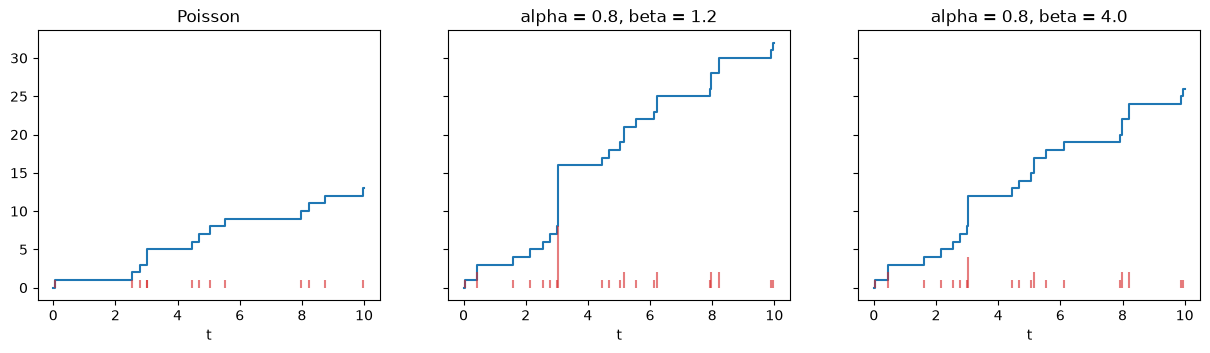

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
graine = 7
for j, (a, b) in enumerate([(0.0, 1.2), (0.8, 1.2), (0.8, 4.0)]):
    r = np.random.default_rng(graine)
    if a == 0:
        tk, sk = simule_poisson(T, mu, r)
    else:
        tk, sk = simule_impact(T, mu, a, b, r)
    ax[j].step(np.r_[0, tk, T], np.r_[0, np.cumsum(sk), sk.sum()], where="post")
    ax[j].vlines(tk, 0, sk, colors="tab:red", alpha=0.6)
    ax[j].set(title=f"alpha = {a}, beta = {b}" if a else "Poisson", xlabel="t")
plt.show()

Lecture : augmenter $\mu$ décale tout proportionnellement ; augmenter $\alpha$ (ou diminuer $\beta$) ajoute des sinistres en grappes juste après les sinistres spontanés, ce qui augmente l'espérance mais surtout la variance et la probabilité d'avoir plusieurs sinistres au même instant. Avec $\beta$ grand l'impact s'éteint vite et on retrouve presque un Poisson.

## 5. Montants des sinistres

On compare cinq lois de même moyenne $m=200$ € pour isoler l'effet de la forme de la loi :

- **discrète « dentaire »** : soin de carie 50 € (55 %), dévitalisation 150 € (25 %), couronne 500 € (15 %), bridge 1200 € (5 %) ;
- **exponentielle** de moyenne 200 ;
- **gamma** $\Gamma(2, 100)$, moins dispersée ;
- **log-normale** $\mathcal{LN}(\ln 200-\tfrac12, 1)$, queue plus lourde ;
- **Pareto** $x_m=109.1$, $a=2.2$ : queue lourde, pas de fonction génératrice des moments, donc pas de coefficient de Lundberg.

           loi  moyenne écart-type      q99
      dentaire    199.9      276.6     1200
 exponentielle    199.9      199.6      920
         gamma    200.5      141.8      668
   log-normale    200.7      262.9     1253
        Pareto    199.8      355.6      877


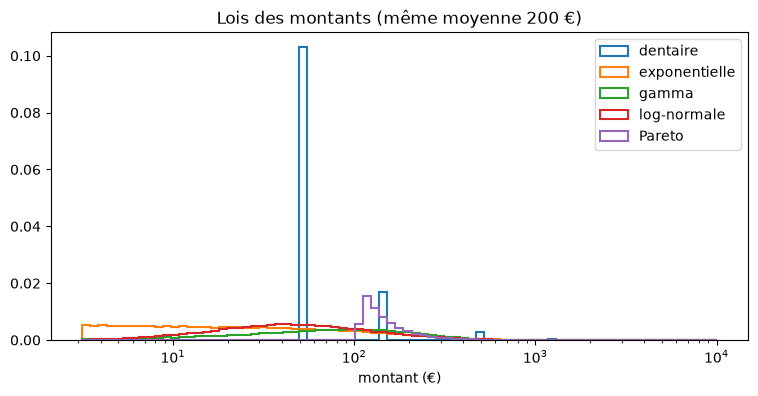

In [7]:
montants = np.array([50, 150, 500, 1200])
probas = np.array([0.55, 0.25, 0.15, 0.05])
m = 200.0

lois = {
    "dentaire": lambda n, r: r.choice(montants, n, p=probas),
    "exponentielle": lambda n, r: r.exponential(m, n),
    "gamma": lambda n, r: r.gamma(2, m / 2, n),
    "log-normale": lambda n, r: r.lognormal(np.log(m) - 0.5, 1, n),
    "Pareto": lambda n, r: m * 1.2 / 2.2 * (1 + r.pareto(2.2, n)),
}

fig, ax = plt.subplots(figsize=(9, 4))
print(f"{'loi':>14} {'moyenne':>8} {'écart-type':>10} {'q99':>8}")
for nom, loi in lois.items():
    y = loi(200000, rng)
    print(f"{nom:>14} {y.mean():8.1f} {y.std():10.1f} {np.quantile(y, 0.99):8.0f}")
    ax.hist(y, bins=np.logspace(0.5, 4, 80), density=True, histtype="step", label=nom, lw=1.5)
ax.set(xscale="log", xlabel="montant (€)", title="Lois des montants (même moyenne 200 €)"); ax.legend()
plt.show()

## 6. Probabilité de ruine

La richesse ne décroît qu'aux sauts, il suffit donc de regarder $R$ juste après chaque saut :
$$\psi(u,T)=\mathbb P\Big(\min_{j}\big(u+c\,t_j-L_j\big)<0\Big)$$
où $L_j$ est le montant cumulé au $j$-ème saut. Comme $u$ n'intervient qu'en translation, une seule simulation donne $\psi(u,T)$ pour tous les $u$.

Prime par le principe de l'espérance sur $[0,T]$ : $cT=(1+\eta)\,\mathbb E[N_T]\,m$ avec $\eta=20\%$.

In [8]:
eta = 0.2
us = np.linspace(0, 3000, 61)

def simule_trajectoires(sim, K):
    temps, sauts, debut = [], [], [0]
    for _ in range(K):
        tk, sk = sim()
        temps.append(tk); sauts.append(sk)
        debut.append(debut[-1] + len(tk))
    return np.concatenate(temps), np.concatenate(sauts), np.array(debut)

def minimum_surplus(traj, c, loi, r):
    temps, sauts, debut = traj
    K = len(debut) - 1
    mins = np.zeros(K)
    if len(temps) == 0:
        return mins
    y = loi(sauts.sum(), r)
    pertes = np.add.reduceat(y, np.r_[0, np.cumsum(sauts)[:-1]])
    cumul = np.cumsum(pertes)
    avant = np.r_[0, cumul][debut[:-1]]
    surplus = c * temps - (cumul - np.repeat(avant, np.diff(debut)))
    nonvide = np.diff(debut) > 0
    mins[nonvide] = np.minimum.reduceat(surplus, debut[:-1][nonvide])
    return np.minimum(mins, 0)

def psi(traj, c, loi, r=rng):
    mins = minimum_surplus(traj, c, loi, r)
    return np.array([(u + mins < 0).mean() for u in us])

K = 20000
traj = {
    "Poisson": simule_trajectoires(lambda: simule_poisson(T, mu, rng), K),
    "impact": simule_trajectoires(lambda: simule_impact(T, mu, alpha, beta, rng), K),
    "Hawkes": simule_trajectoires(lambda: hawkes_ogata(T, mu, alpha, beta, rng), K),
}
EN = {"Poisson": mu * T, "impact": esperance_impact(T, mu, alpha, beta), "Hawkes": esperance_hawkes(T, mu, alpha, beta)}
c = {k: (1 + eta) * EN[k] * m / T for k in EN}
print({k: round(v, 1) for k, v in c.items()})

{'Poisson': 240.0, 'impact': np.float64(533.3), 'Hawkes': np.float64(602.2)}


**Validation sur le cas du cours** : Poisson + sinistres exponentiels, sur un horizon long ($T=200$), on doit retrouver $\psi(u)=\frac{1}{1+\eta}e^{-\eta u/((1+\eta)m)}$.

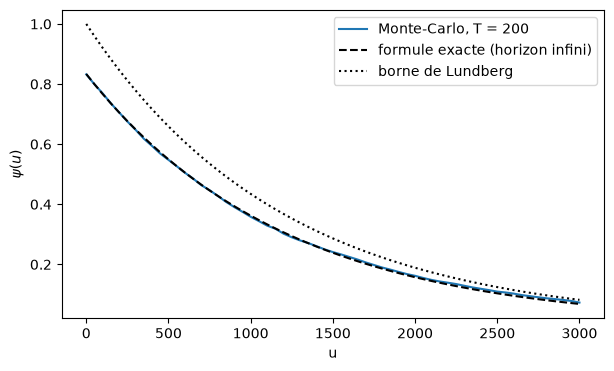

In [9]:
val = simule_trajectoires(lambda: simule_poisson(200.0, mu, rng), 5000)
p_val = psi(val, c["Poisson"], lois["exponentielle"])
plt.figure(figsize=(7, 4))
plt.plot(us, p_val, label="Monte-Carlo, T = 200")
plt.plot(us, np.exp(-eta * us / ((1 + eta) * m)) / (1 + eta), "k--", label="formule exacte (horizon infini)")
plt.plot(us, np.exp(-(1 / m - mu / c["Poisson"]) * us), "k:", label="borne de Lundberg")
plt.xlabel("u"); plt.ylabel(r"$\psi(u)$"); plt.legend(); plt.show()

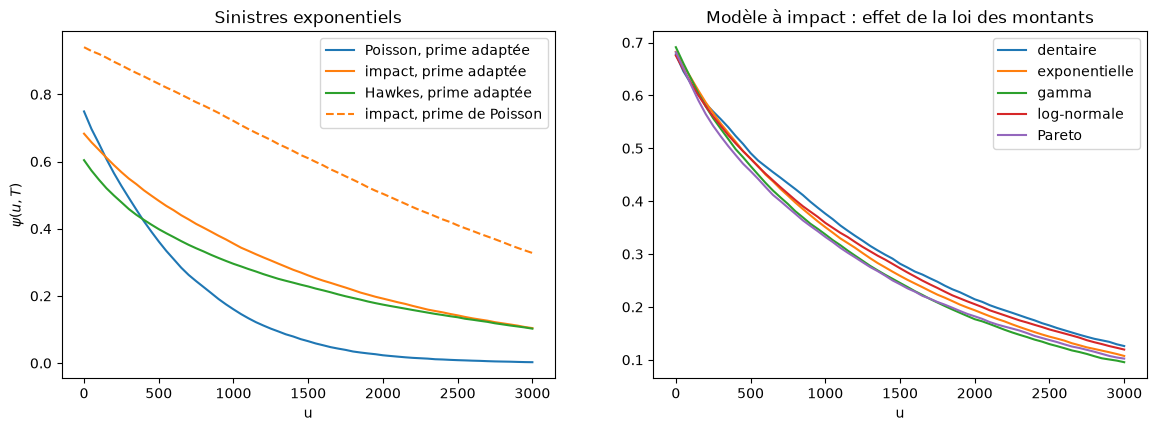

psi(u=1000, T=10)
           loi |  Poisson   impact   Hawkes |  impact, prime Poisson
      dentaire |    0.226    0.384    0.330 |                  0.710
 exponentielle |    0.157    0.354    0.296 |                  0.722


         gamma |    0.110    0.340    0.276 |                  0.726
   log-normale |    0.177    0.360    0.305 |                  0.700
        Pareto |    0.111    0.330    0.274 |                  0.704


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for k in traj:
    ax[0].plot(us, psi(traj[k], c[k], lois["exponentielle"]), label=f"{k}, prime adaptée")
ax[0].plot(us, psi(traj["impact"], c["Poisson"], lois["exponentielle"]), "--", c="tab:orange", label="impact, prime de Poisson")
ax[0].set(xlabel="u", ylabel=r"$\psi(u,T)$", title="Sinistres exponentiels"); ax[0].legend()
for nom, loi in lois.items():
    ax[1].plot(us, psi(traj["impact"], c["impact"], loi), label=nom)
ax[1].set(xlabel="u", title="Modèle à impact : effet de la loi des montants"); ax[1].legend()
plt.show()

u0 = 1000
i0 = np.searchsorted(us, u0)
print(f"psi(u={u0}, T={T:.0f})")
print(f"{'loi':>14} | {'Poisson':>8} {'impact':>8} {'Hawkes':>8} | {'impact, prime Poisson':>22}")
for nom, loi in lois.items():
    ligne = [psi(traj[k], c[k], loi)[i0] for k in traj]
    print(f"{nom:>14} | " + " ".join(f"{p:8.3f}" for p in ligne) + f" | {psi(traj['impact'], c['Poisson'], loi)[i0]:22.3f}")

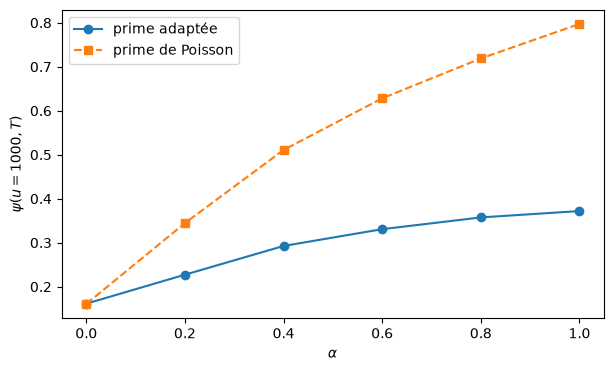

In [11]:
alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
p_alpha = []
for a in alphas:
    if a == 0:
        tr = simule_trajectoires(lambda: simule_poisson(T, mu, rng), 10000)
    else:
        tr = simule_trajectoires(lambda: simule_impact(T, mu, a, beta, rng), 10000)
    ca = (1 + eta) * esperance_impact(T, mu, a, beta) * m / T
    p_alpha.append((psi(tr, ca, lois["exponentielle"])[i0], psi(tr, c["Poisson"], lois["exponentielle"])[i0]))
p_alpha = np.array(p_alpha)
plt.figure(figsize=(7, 4))
plt.plot(alphas, p_alpha[:, 0], "o-", label="prime adaptée")
plt.plot(alphas, p_alpha[:, 1], "s--", label="prime de Poisson")
plt.xlabel(r"$\alpha$"); plt.ylabel(fr"$\psi(u={u0},T)$"); plt.legend(); plt.show()

Lecture :
- la méthode Monte-Carlo est validée : sur le cas du cours on retrouve la formule exacte et la borne de Lundberg est respectée ;
- à prime adaptée (même chargement de 20 %), la ruine est un peu moins probable que pour Poisson quand $u$ est très petit (la prime plus élevée protège au début, avant que les grappes ne démarrent), mais bien plus probable dès que $u$ dépasse quelques centaines d'euros : la prime corrige la moyenne, pas la surdispersion ;
- si l'on garde la prime calibrée sur Poisson, la probabilité de ruine augmente très fortement avec $\alpha$ ;
- à moyenne égale, la loi des montants a un effet plus faible que le processus de comptage dans le modèle à impact. La loi dentaire (bridges rares mais chers) donne la ruine la plus élevée, la gamma la plus faible. La Pareto ne ressort pas ici : la plupart de ses montants sont proches de $x_m$ et sa queue lourde ne pèse que pour de très grands $u$ (ruine causée par un seul sinistre énorme), hors de notre grille.

### 6.2 Comparaison à nombre moyen de sinistres égal

La comparaison précédente mélange deux effets : le modèle à impact a plus de sinistres en moyenne (22 contre 10) **et** des grappes. Pour isoler l'effet des grappes, on compare à un Poisson d'intensité $\lambda_{eq}=\mathbb E[N_T]/T$ : même nombre moyen de sinistres, donc même prime par le principe de l'espérance.

lambda_eq = 2.222
             Poisson : E[N_T] =   9.99   Var(N_T) =   10.0   c = 240.0
  Poisson équivalent : E[N_T] =  22.28   Var(N_T) =   22.4   c = 533.3
              impact : E[N_T] =  22.06   Var(N_T) =  109.1   c = 533.3


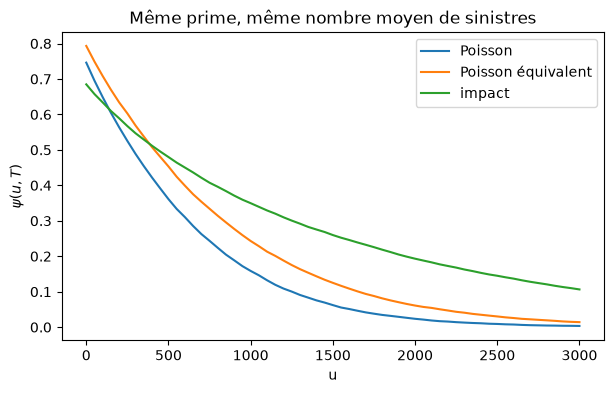

psi(u=1000, T=10) à prime égale
           loi | Poisson équivalent   impact


      dentaire |              0.325    0.379
 exponentielle |              0.252    0.354
         gamma |              0.189    0.337
   log-normale |              0.267    0.357


        Pareto |              0.187    0.333


In [12]:
lam_eq = esperance_impact(T, mu, alpha, beta) / T
traj["Poisson équivalent"] = simule_trajectoires(lambda: simule_poisson(T, lam_eq, rng), K)
EN["Poisson équivalent"] = lam_eq * T
c["Poisson équivalent"] = c["impact"]
NT = {k: np.diff(np.r_[0, np.cumsum(traj[k][1])][traj[k][2]]) for k in traj}
print(f"lambda_eq = {lam_eq:.3f}")
for k in ["Poisson", "Poisson équivalent", "impact"]:
    print(f"{k:>20} : E[N_T] = {NT[k].mean():6.2f}   Var(N_T) = {NT[k].var():6.1f}   c = {c[k]:.1f}")

plt.figure(figsize=(7, 4))
for k, st in [("Poisson", "-"), ("Poisson équivalent", "-"), ("impact", "-")]:
    plt.plot(us, psi(traj[k], c[k], lois["exponentielle"]), st, label=k)
plt.xlabel("u"); plt.ylabel(r"$\psi(u,T)$"); plt.title("Même prime, même nombre moyen de sinistres"); plt.legend(); plt.show()

print(f"psi(u={u0}, T={T:.0f}) à prime égale")
print(f"{'loi':>14} | {'Poisson équivalent':>18} {'impact':>8}")
for nom, loi in lois.items():
    print(f"{nom:>14} | {psi(traj['Poisson équivalent'], c['impact'], loi)[i0]:18.3f} {psi(traj['impact'], c['impact'], loi)[i0]:8.3f}")

À prime égale et à nombre moyen de sinistres égal, le modèle à impact ruine nettement plus que le Poisson équivalent (avec des montants exponentiels, environ 0,35 contre 0,25 pour $u=1000$). C'est l'effet propre des grappes : la variance de $N_T$ est environ 5 fois plus grande pour la même moyenne. On remarque aussi que la loi des montants fait beaucoup varier la ruine dans le cas Poisson (de 0,19 à 0,33), beaucoup moins dans le modèle à impact (de 0,33 à 0,38) : quand les sinistres arrivent en grappes, c'est le comptage qui domine le risque.

### 6.3 Un principe de prime qui tient compte de la variance

Principe de la variance : $\pi_T=\mathbb E[S_T]+\delta\operatorname{Var}(S_T)$ avec
$$\operatorname{Var}(S_T)=\mathbb E[N_T]\operatorname{Var}(Y)+\operatorname{Var}(N_T)\,\mathbb E[Y]^2 .$$
On calibre $\delta$ pour retrouver le chargement de 20 % dans le cas Poisson + exponentielle, puis on garde ce $\delta$ pour tous les modèles et toutes les lois.

In [13]:
def var_S(k, loi):
    y = loi(200000, rng)
    return NT[k].mean() * y.var() + NT[k].var() * y.mean() ** 2

delta = eta * EN["Poisson"] * m / (mu * T * 2 * m ** 2)
c_var = {(k, nom): (NT[k].mean() * m + delta * var_S(k, loi)) / T for k in ["Poisson", "Poisson équivalent", "impact"] for nom, loi in lois.items()}

print(f"delta = {delta:.2e}")
print(f"{'loi':>14} | {'c Poisson':>9} {'c impact (esp.)':>15} {'c impact (var.)':>15} | {'psi impact (esp.)':>17} {'psi impact (var.)':>17}")
for nom, loi in lois.items():
    print(f"{nom:>14} | {c_var[('Poisson', nom)]:9.1f} {c['impact']:15.1f} {c_var[('impact', nom)]:15.1f} | "
          f"{psi(traj['impact'], c['impact'], loi)[i0]:17.3f} {psi(traj['impact'], c_var[('impact', nom)], loi)[i0]:17.3f}")

delta = 5.00e-04
           loi | c Poisson c impact (esp.) c impact (var.) | psi impact (esp.) psi impact (var.)
      dentaire |     258.7           533.3           743.3 |             0.382             0.233
 exponentielle |     239.9           533.3           703.6 |             0.351             0.221
         gamma |     229.7           533.3           681.4 |             0.339             0.219


   log-normale |     253.1           533.3           731.9 |             0.356             0.221
        Pareto |     249.5           533.3           725.3 |             0.328             0.197


Avec le principe de la variance, la prime du modèle à impact passe d'environ 533 à 680–745 € par an selon la loi, et la probabilité de ruine pour $u=1000$ redescend d'environ 0,35 à 0,20–0,23, proche du niveau du modèle de Poisson. La prime s'adapte aussi à la loi : la loi dentaire, la plus dispersée, est la plus chargée. C'est la recommandation à faire au N+1 : tarifer avec un chargement qui dépend de la variance, et donc estimer $\alpha$ et $\beta$.

### 6.4 Horizon long

Les résultats du cours portent sur $\psi(u)=\mathbb P(\tau<\infty)$. On regarde $\psi(u,T)$ pour des horizons croissants. Sur un horizon long, la prime doit couvrir le régime permanent : on prend $c=(1+\eta)\,\mu(1+2\alpha/\beta)\,m$ (taux limite de sinistres). Pour Poisson, la formule exacte $\psi(u)=\frac1{1+\eta}e^{-\eta u/((1+\eta)m)}$ ne dépend pas de l'intensité, elle sert de repère.

T =  10 : psi(u=1000) Poisson = 0.250   impact = 0.337


T =  50 : psi(u=1000) Poisson = 0.345   impact = 0.505


T = 100 : psi(u=1000) Poisson = 0.367   impact = 0.537


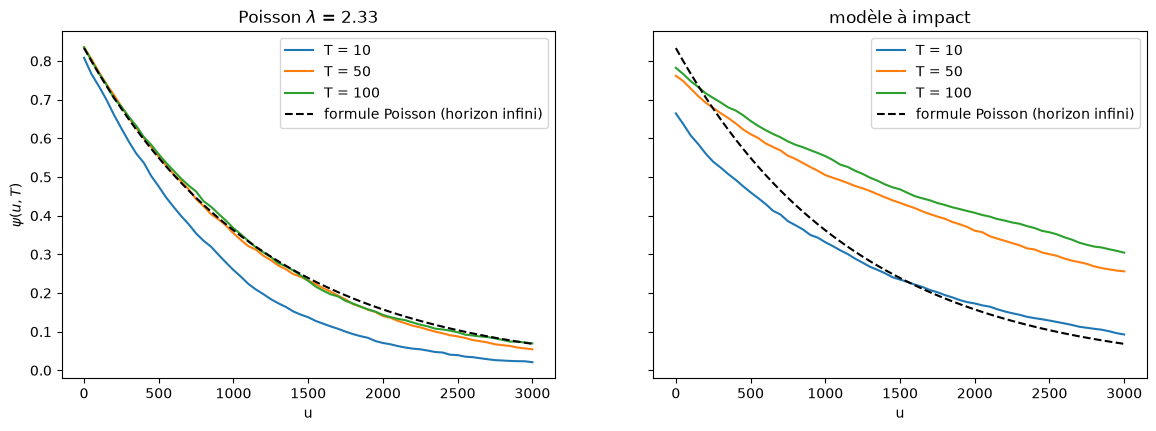

In [14]:
c_inf = (1 + eta) * mu * (1 + facteur * alpha / beta) * m
lam_inf = mu * (1 + facteur * alpha / beta)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for Tl in [10, 50, 100]:
    tp = simule_trajectoires(lambda: simule_poisson(Tl, lam_inf, rng), 3000)
    ti = simule_trajectoires(lambda: simule_impact(Tl, mu, alpha, beta, rng), 3000)
    ax[0].plot(us, psi(tp, c_inf, lois["exponentielle"]), label=f"T = {Tl}")
    ax[1].plot(us, psi(ti, c_inf, lois["exponentielle"]), label=f"T = {Tl}")
    print(f"T = {Tl:3d} : psi(u={u0}) Poisson = {psi(tp, c_inf, lois['exponentielle'])[i0]:.3f}   impact = {psi(ti, c_inf, lois['exponentielle'])[i0]:.3f}")
for a in ax:
    a.plot(us, np.exp(-eta * us / ((1 + eta) * m)) / (1 + eta), "k--", label="formule Poisson (horizon infini)")
    a.set(xlabel="u"); a.legend()
ax[0].set(title=fr"Poisson $\lambda$ = {lam_inf:.2f}", ylabel=r"$\psi(u,T)$")
ax[1].set(title="modèle à impact")
plt.show()

Pour Poisson, $\psi(u,T)$ converge vers la formule exacte du cours (0,367 en $T=100$ contre 0,362). Pour le modèle à impact, la ruine continue d'augmenter avec l'horizon et se stabilise nettement au-dessus (environ 0,54 en $T=100$) avec pourtant la même prime et le même taux moyen de sinistres. En particulier, la borne de Lundberg calculée comme si le comptage était un Poisson ($e^{-Ru}\approx0{,}43$ pour $u=1000$) n'est plus valable : les outils du cours sous-estiment le risque de ce modèle.

### 6.5 Remarque sur les sauts de taille $k>1$

Quand un point est dans la zone d'impact de plusieurs sinistres spontanés, $N$ saute de $k>1$. On a choisi d'y associer $k$ sinistres de montants indépendants survenus au même instant : c'est cohérent avec la définition de $N^{(2)}$ qui compte des couples (parent, enfant), et avec Wald puisque $\mathbb E[S_T]=\mathbb E[N_T]\,m$ reste vrai. Une autre lecture possible serait un seul sinistre de montant multiplié ; elle garderait la même espérance mais augmenterait encore la variance.

## 7. Propriétés du cours : que deviennent-elles ?

| Propriété | Poisson | Modèle à impact |
|---|---|---|
| accroissements indépendants | oui | non (un sinistre influence le futur) |
| accroissements stationnaires | oui | non, $\mathbb E[N_t]$ n'est pas linéaire au début |
| loi de $N_t$ | $\mathcal P(\mu t)$ | pas de forme simple ; $\operatorname{Var}>\mathbb E$ |
| sauts de taille 1 | oui | non (sinistres simultanés) |
| $\mathbb E[N_t]$ | $\mu t$ | $\mu t+2\frac{\mu\alpha}{\beta}\big(t-\frac{1-e^{-\beta t}}{\beta}\big)$ |
| Wald $\mathbb E[S_t]=\mathbb E[N_t]m$ | oui | oui ($Y$ indépendants de $N$) |
| profit net | $c>\mu m$ | $c>\mu(1+2\alpha/\beta)\,m$ |
| formule de ruine / Lundberg | oui (Lundberg, cas exponentiel exact) | pas de formule : Monte-Carlo |
| à moyenne égale | référence | ruine plus élevée (grappes) |
| $\operatorname{Var}(S_t)$ | $\mu t\,\mathbb E[Y^2]$ | $\mathbb E[N_t]\operatorname{Var}(Y)+\operatorname{Var}(N_t)\,m^2$ |

## 8. Synthèse pour le N+1

- Le modèle à impact garde la structure de Cramér-Lundberg mais remplace l'arrivée « sans mémoire » des sinistres par des sinistres spontanés (fréquence $\mu$) qui déclenchent des sinistres induits pendant une durée de l'ordre de $1/\beta$, avec une force $\alpha$.
- L'espérance du nombre de sinistres est explicite à toute date et vérifiée par simulation ; elle croît de $\mu t$ vers une pente $\mu(1+2\alpha/\beta)$. C'est une approximation à deux générations du processus de Hawkes.
- Ce qu'apporte le modèle par rapport à Poisson : des grappes de sinistres, une variance bien plus grande que la moyenne, et des sinistres simultanés. Une tarification de type Poisson sous-estime alors fortement le risque de ruine.
- À nombre moyen de sinistres égal et prime égale, le modèle à impact ruine nettement plus qu'un Poisson : c'est l'effet propre des grappes, et il persiste sur un horizon long où la borne de Lundberg du cas Poisson n'est plus valable.
- Recommandation : un principe de prime fondé sur la variance ramène la probabilité de ruine près du niveau Poisson ; il faut donc estimer $\alpha$ et $\beta$ sur les données et charger la prime en conséquence.
- Limites : seulement deux générations d'impact, sauts de taille $>1$, et une convention (facteur 2 du sujet ou $\frac1{2!}$ de l'article) à valider.